# Step 6: Explainability with SHAP
## AI-Assisted Health Risk Prediction for Life Insurance Underwriting

SHAP (SHapley Additive exPlanations) attributes each prediction to its input
features, giving both **global** (which factors matter overall) and **local**
(why THIS applicant got THIS risk) explanations.

We explain **XGBoost** (our best model) using the fast exact `TreeExplainer`.
The per-applicant explanations produced here are saved and become the input to
the **LLM underwriting report** in Step 7 (model + SHAP -> human-readable summary).

**This notebook:**
1. Load XGBoost model + model-ready data
2. Compute SHAP values (TreeExplainer)
3. Global: summary (beeswarm) + bar importance
4. Dependence plots for top features
5. Local: waterfall/force explanations for example applicants
6. Compare SHAP importance vs GLM coefficients
7. Save per-applicant SHAP explanations for the LLM step

## 6.1 Setup & Load Model + Data

In [1]:
import pandas as pd
import numpy as np
import json
import joblib
from pathlib import Path

import matplotlib.pyplot as plt
import shap

print(f'shap {shap.__version__}')

shap 0.52.0


In [2]:
# Robust path resolution (works from project root or Code/)
def find_dir(name):
    for base in [Path('.'), Path('..'), Path('..') / '..']:
        candidate = base / 'data' / name
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(f'Could not locate data/{name}. Run notebooks 03-05 first.')

MODEL_DIR = find_dir('model_ready')
RESULTS_DIR = MODEL_DIR.parent / 'results'
FIG_DIR = MODEL_DIR.parent / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Data
X_train = pd.read_parquet(MODEL_DIR / 'X_train.parquet')
X_test = pd.read_parquet(MODEL_DIR / 'X_test.parquet')
y_test = pd.read_parquet(MODEL_DIR / 'y_test.parquet')['MORTSTAT']

# Best model (XGBoost) from Step 5
xgb_clf = joblib.load(RESULTS_DIR / 'xgboost_model.joblib')
print(f'Loaded XGBoost. Test set: {X_test.shape}')

Loaded XGBoost. Test set: (3716, 84)


In [4]:
# Clean feature names for readable plots (strip the 'num__'/'cat__' prefixes)
def clean_name(n):
    return n.replace('num__', '').replace('cat__', '')

display_names = [clean_name(c) for c in X_test.columns]
X_test_disp = X_test.copy()
X_test_disp.columns = display_names
print('Example cleaned names:', display_names[:6])

Example cleaned names: ['AGE', 'POVERTY_INCOME_RATIO', 'BMXBMI', 'BMXWAIST', 'BMXHT', 'BMXWT']


## 6.2 Compute SHAP Values

`TreeExplainer` computes exact SHAP values efficiently for tree ensembles.
SHAP values are in **log-odds** space (the XGBoost margin): positive pushes the
prediction toward 'deceased', negative toward 'alive'.

In [5]:
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X_test)

print(f'SHAP values shape: {shap_values.shape}')
print(f'Base (expected) value in log-odds: {explainer.expected_value:.4f}')

SHAP values shape: (3716, 84)
Base (expected) value in log-odds: 0.1275


## 6.3 Global Explanation : Feature Importance

**Beeswarm summary:** each dot is one applicant; horizontal position is that
feature's SHAP value (impact on risk). Color = feature value (red high, blue low).
**Bar plot:** mean |SHAP| - the overall importance ranking.

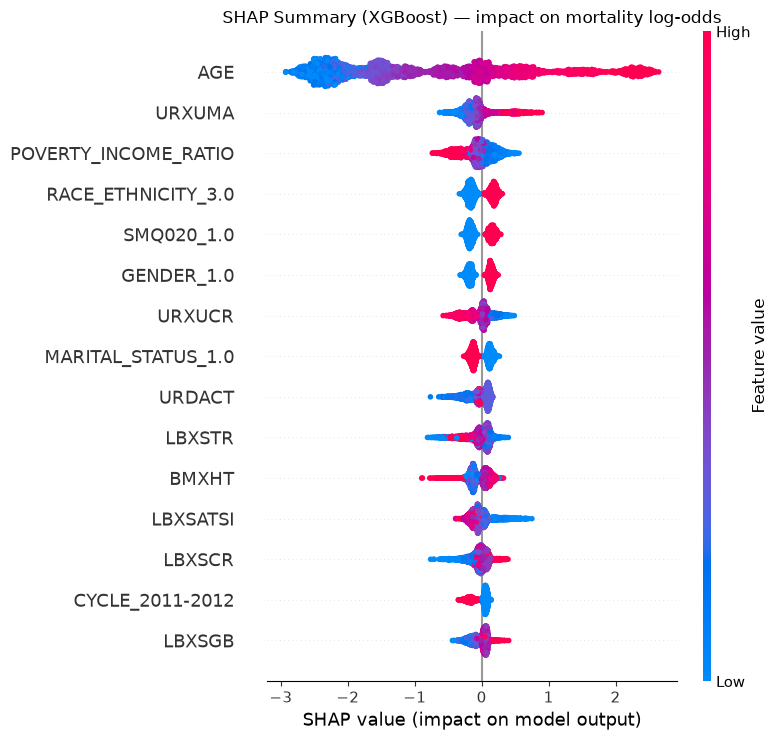

In [10]:
# Beeswarm summary plot
shap.summary_plot(shap_values, X_test_disp, show=False, max_display=15)
plt.title('SHAP Summary (XGBoost) — impact on mortality log-odds')
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_summary_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

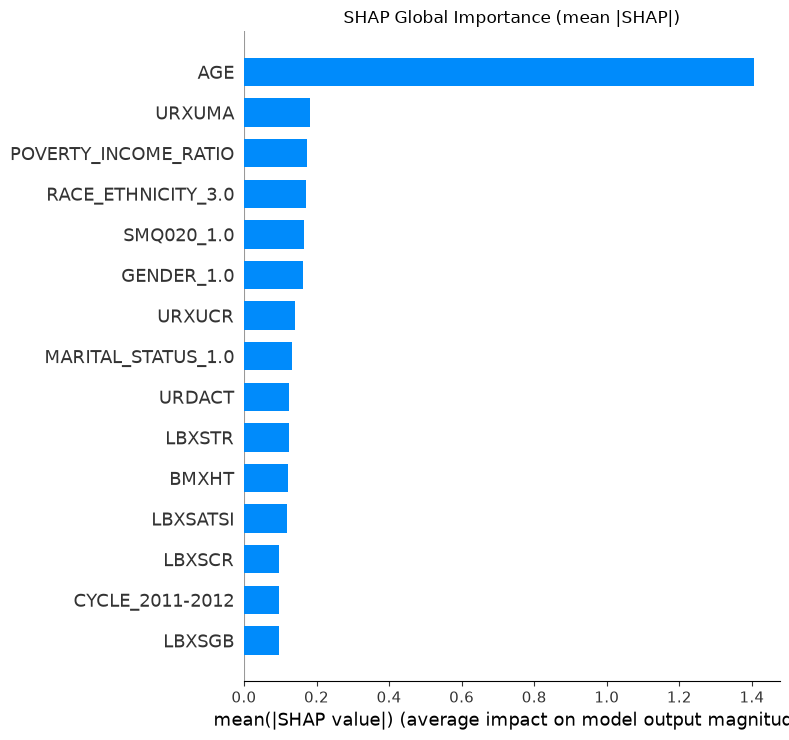

In [15]:
# Bar plot: mean absolute SHAP value
shap.summary_plot(shap_values, X_test_disp, plot_type='bar', show=False, max_display=15)
plt.title('SHAP Global Importance (mean |SHAP|)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_importance_bar.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Numeric importance table (mean |SHAP|)
mean_abs = np.abs(shap_values).mean(axis=0)
shap_importance = pd.DataFrame({
    'feature': display_names,
    'mean_abs_shap': mean_abs,
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
shap_importance.head(15)

,feature,mean_abs_shap
0,AGE,1.407008
1,URXUMA,0.182762
2,POVERTY_INCOME_RATIO,0.172401
3,RACE_ETHNICITY_3.0,0.170271
4,SMQ020_1.0,0.166284
5,GENDER_1.0,0.161735
6,URXUCR,0.139945
7,MARITAL_STATUS_1.0,0.131899
8,URDACT,0.124968
9,LBXSTR,0.124839


## 6.4 Dependence Plots (Top Features)

How a feature's value maps to its SHAP impact, reveals non-linear thresholds
(e.g., risk rising sharply past a certain age). SHAP auto-colors by the feature
it most interacts with.

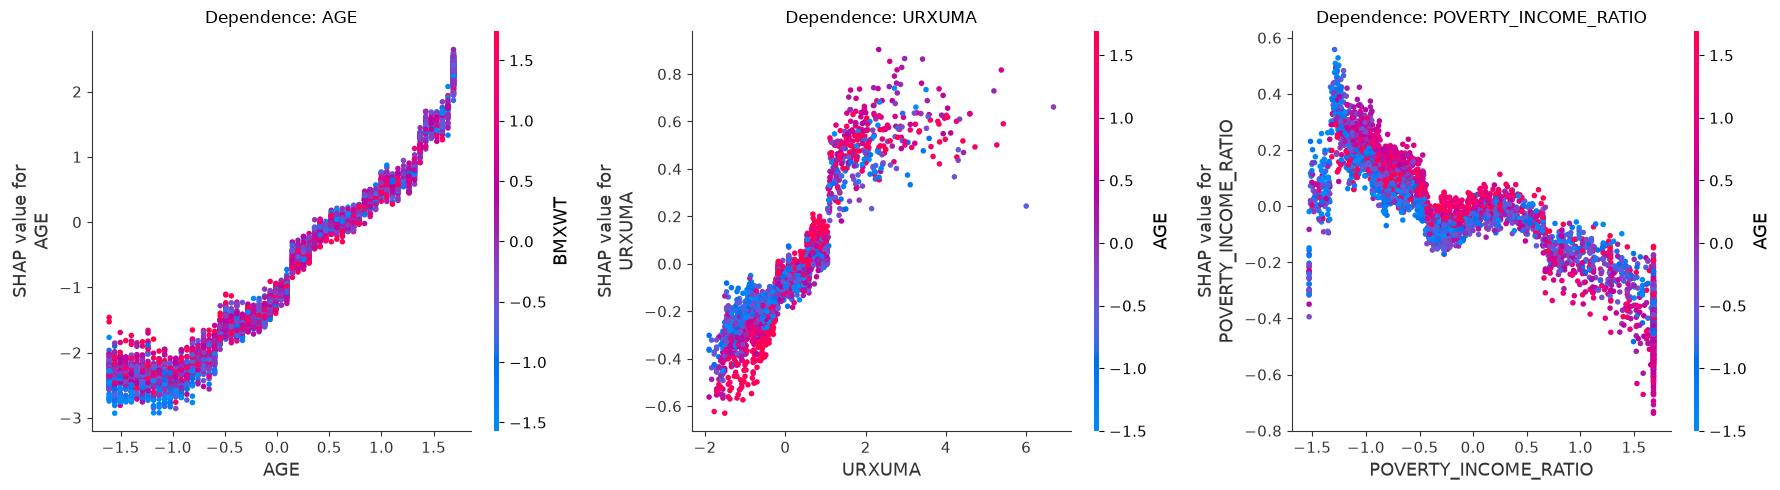

In [8]:
top_feats = shap_importance['feature'].head(3).tolist()
fig, axes = plt.subplots(1, len(top_feats), figsize=(6 * len(top_feats), 5))
if len(top_feats) == 1:
    axes = [axes]
for ax, feat in zip(axes, top_feats):
    idx = display_names.index(feat)
    shap.dependence_plot(idx, shap_values, X_test_disp,
                         ax=ax, show=False, interaction_index='auto')
    ax.set_title(f'Dependence: {feat}')
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_dependence_top3.png', dpi=150, bbox_inches='tight')
plt.show()

## 6.5 Local Explanations : Individual Applicants

The core of the underwriting use-case: *why* did the model assign this person
their risk? We show waterfall plots for a **high-risk** and a **low-risk**
applicant. Each bar is a feature pushing the prediction up (red) or down (blue)
from the base rate.

In [16]:
# Predicted risk on the test set
test_prob = xgb_clf.predict_proba(X_test)[:, 1]

# Pick a clear high-risk and low-risk example
high_idx = int(np.argmax(test_prob))
low_idx = int(np.argmin(test_prob))
print(f'High-risk applicant: row {high_idx}, predicted risk {test_prob[high_idx]:.3f}, actual={y_test.iloc[high_idx]}')
print(f'Low-risk  applicant: row {low_idx}, predicted risk {test_prob[low_idx]:.3f}, actual={y_test.iloc[low_idx]}')

High-risk applicant: row 2609, predicted risk 0.994, actual=1
Low-risk  applicant: row 3620, predicted risk 0.002, actual=0


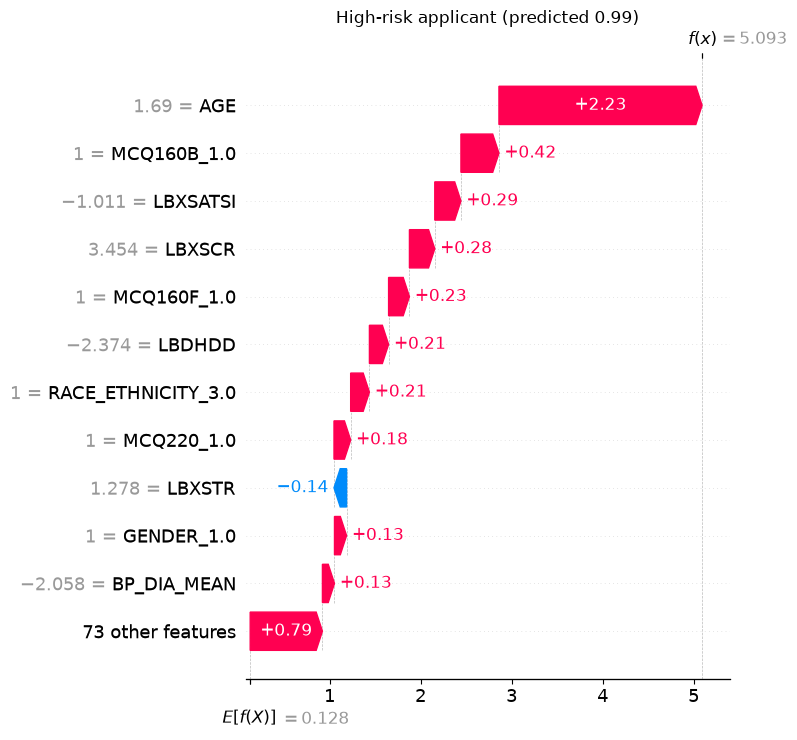

In [17]:
# Waterfall for the HIGH-risk applicant
expl_high = shap.Explanation(
    values=shap_values[high_idx],
    base_values=explainer.expected_value,
    data=X_test_disp.iloc[high_idx].values,
    feature_names=display_names,
)
shap.plots.waterfall(expl_high, max_display=12, show=False)
plt.title(f'High-risk applicant (predicted {test_prob[high_idx]:.2f})')
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_waterfall_highrisk.png', dpi=150, bbox_inches='tight')
plt.show()

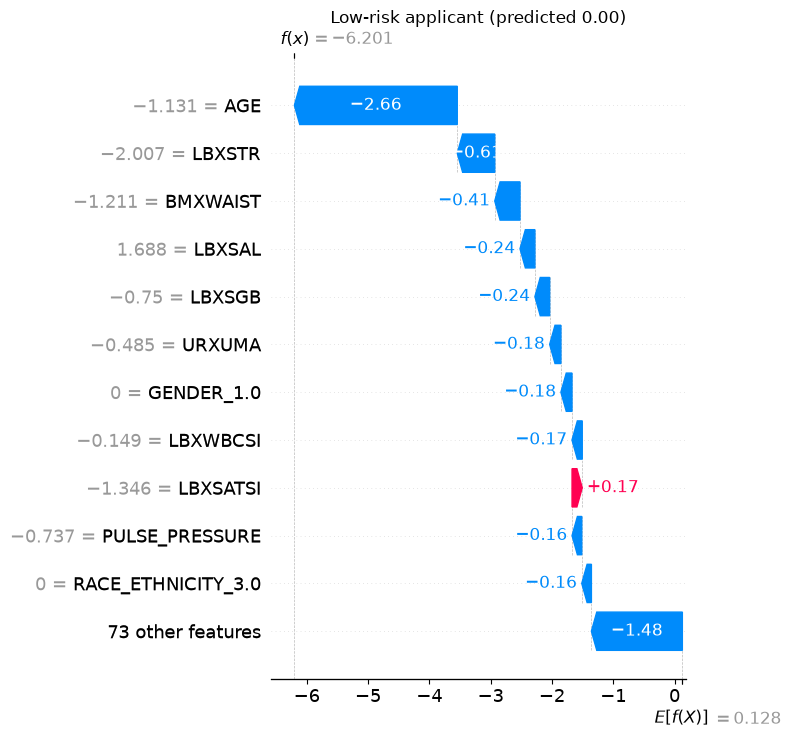

In [18]:
# Waterfall for the LOW-risk applicant
expl_low = shap.Explanation(
    values=shap_values[low_idx],
    base_values=explainer.expected_value,
    data=X_test_disp.iloc[low_idx].values,
    feature_names=display_names,
)
shap.plots.waterfall(expl_low, max_display=12, show=False)
plt.title(f'Low-risk applicant (predicted {test_prob[low_idx]:.2f})')
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_waterfall_lowrisk.png', dpi=150, bbox_inches='tight')
plt.show()

## 6.6 SHAP Importance vs GLM Coefficients

Do the black-box (XGBoost/SHAP) and interpretable (GLM) models agree on what
drives mortality risk? Agreement builds trust in both.

In [19]:
glm_coefs = pd.read_csv(RESULTS_DIR / 'glm_coefficients.csv')
glm_coefs['feature'] = glm_coefs['feature'].apply(clean_name)
glm_top = glm_coefs.reindex(glm_coefs['coefficient'].abs().sort_values(ascending=False).index)

compare = pd.DataFrame({
    'SHAP_rank': shap_importance['feature'].head(10).values,
})
compare['GLM_rank'] = glm_top['feature'].head(10).values
print('Top 10 features: SHAP (XGBoost) vs GLM')
compare

Top 10 features: SHAP (XGBoost) vs GLM


,SHAP_rank,GLM_rank
0,AGE,AGE
1,URXUMA,RACE_ETHNICITY_3.0
2,POVERTY_INCOME_RATIO,BMXBMI
3,RACE_ETHNICITY_3.0,MCQ160B_2.0
4,SMQ020_1.0,MARITAL_STATUS_1.0
5,GENDER_1.0,MCQ160B_1.0
6,URXUCR,URXUMA
7,MARITAL_STATUS_1.0,RACE_ETHNICITY_1.0
8,URDACT,BMXWT
9,LBXSTR,GENDER_2.0


## 6.7 Save Per-Applicant SHAP Explanations (for Step 7 LLM)

For a sample of test applicants we save a structured record: predicted risk +
the top contributing features with their SHAP values and actual feature values.
This JSON is exactly what the LLM will turn into a human-readable underwriting
summary, the LLM explains, it does not predict.

In [20]:
def top_contributions(i, k=8):
    contribs = sorted(
        [(display_names[j], float(shap_values[i, j]), float(X_test_disp.iloc[i, j]))
         for j in range(len(display_names))],
        key=lambda t: abs(t[1]), reverse=True)[:k]
    return [{'feature': f, 'shap_value': round(s, 4),
             'feature_value': round(v, 4),
             'direction': 'increases_risk' if s > 0 else 'decreases_risk'}
            for f, s, v in contribs]

# Sample: highest-risk, lowest-risk, and some mid-risk applicants
sample_idx = [high_idx, low_idx] + list(np.argsort(test_prob)[len(test_prob)//2 : len(test_prob)//2 + 6])
sample_idx = list(dict.fromkeys(int(i) for i in sample_idx))  # dedupe, keep order

explanations = []
for i in sample_idx:
    explanations.append({
        'applicant_id': int(X_test.index[i]),
        'predicted_risk': round(float(test_prob[i]), 4),
        'base_rate_logodds': round(float(explainer.expected_value), 4),
        'actual_outcome': int(y_test.iloc[i]),
        'top_contributions': top_contributions(i),
    })

out_path = RESULTS_DIR / 'shap_explanations.json'
with open(out_path, 'w') as f:
    json.dump(explanations, f, indent=2)

# Also save global SHAP importance for the report
shap_importance.to_csv(RESULTS_DIR / 'shap_importance.csv', index=False)

print(f'Saved {len(explanations)} applicant explanations -> {out_path}')
print('\nExample record:')
print(json.dumps(explanations[0], indent=2))

Saved 8 applicant explanations -> <PROJECT_ROOT>\data\results\shap_explanations.json

Example record:
{
  "applicant_id": 118,
  "predicted_risk": 0.9939,
  "base_rate_logodds": 0.1275,
  "actual_outcome": 1,
  "top_contributions": [
    {
      "feature": "AGE",
      "shap_value": 2.2319,
      "feature_value": 1.6905,
      "direction": "increases_risk"
    },
    {
      "feature": "MCQ160B_1.0",
      "shap_value": 0.4177,
      "feature_value": 1.0,
      "direction": "increases_risk"
    },
    {
      "feature": "LBXSATSI",
      "shap_value": 0.2874,
      "feature_value": -1.0113,
      "direction": "increases_risk"
    },
    {
      "feature": "LBXSCR",
      "shap_value": 0.2784,
      "feature_value": 3.4537,
      "direction": "increases_risk"
    },
    {
      "feature": "MCQ160F_1.0",
      "shap_value": 0.229,
      "feature_value": 1.0,
      "direction": "increases_risk"
    },
    {
      "feature": "LBDHDD",
      "shap_value": 0.2108,
      "feature_value": -2.3

## Next Steps

SHAP explanations are saved to `data/results/shap_explanations.json`.

**Proceed to Notebook 07: Agentic LLM Underwriting Report**
- Feed each applicant's prediction + SHAP contributions to an LLM (Qwen/Llama/Gemini)
- Generate a human-readable underwriting summary per applicant
- The LLM explains the model output only; it does NOT make the mortality prediction